# Trabalho Final — Aprendizagem de Máquina (IFPR)
## Classificação da direção diária da Solana

Notebook de entrega, organizado pelas **7 etapas** do plano de atividades:

1. Escolha e descrição da base
2. Análise exploratória
3. Pré-processamento
4. Divisão dos dados
5. Treinamento
6. Avaliação e comparação
7. Uso do modelo

Apêndice (opcional): regressão da volatilidade futura.

**Base oficial:** `data/snapshot/solana_365d.csv` — série congelada de 2025-09-01 a 2026-08-31,
entregue junto com o código. O notebook **não consulta a API** (só na célula opcional da Etapa 7),
então qualquer pessoa reproduz exatamente os mesmos números.

**Código:** coleta, limpeza e construção de atributos reaproveitam as funções de `src/`
(`collect.py`, `preprocess.py`, `features.py`). Já as etapas 4 a 7 — divisão, pipelines,
treino, métricas e uso do modelo — estão **escritas aqui, por extenso**, com os mesmos
hiperparâmetros de `src/classification.py` (semente 42, KNN k=15, árvore `max_depth=3`,
`TimeSeriesSplit` com 5 partições). Por isso os números batem com `reports/classificacao.md`.

> **Trabalho acadêmico.** Nada aqui é recomendação de investimento. As saídas dos modelos são
> estimativas condicionadas ao período analisado, não afirmações sobre o futuro.

In [1]:
# ---------------------------------------------------------------------
# Configuração geral: bibliotecas, caminhos e hiperparâmetros
# ---------------------------------------------------------------------
from __future__ import annotations

import io
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# O notebook funciona tanto aberto de notebooks/ quanto da raiz do projeto
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))   # permite importar os módulos de src/

import collect      # noqa: E402  leitura do snapshot congelado
import preprocess   # noqa: E402  limpeza e diagnóstico de qualidade
import features     # noqa: E402  13 atributos + rótulo, sem vazamento

# Hiperparâmetros — IDÊNTICOS aos de src/classification.py
SEMENTE = 42
FRACAO_TREINO = 0.70     # 70% iniciais = treino, 30% finais = teste
N_SPLITS = 5             # partições do TimeSeriesSplit dentro do treino
K_VIZINHOS = 15          # KNN
PROFUNDIDADE_ARVORE = 3  # árvore de decisão rasa

np.random.seed(SEMENTE)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 30)

# Estilo dos gráficos: grade discreta e as duas cores categóricas do projeto
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
COR_1 = "#2a78d6"   # azul   — classe 1 / split temporal
COR_2 = "#eb6834"   # laranja — classe 0 / split embaralhado
RAMPA_AZUL = LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#86b6ef", "#2a78d6", "#104281"])

print(f"Raiz do projeto: {RAIZ}")

Raiz do projeto: c:\Users\Aluno\projeto-cripto


---
# Etapa 1 — Escolha e descrição da base

### Fonte dos dados

- **API pública CoinGecko**, endpoint
  [`/coins/{id}/market_chart`](https://docs.coingecko.com/reference/coins-id-market-chart)
  com `id=solana`, `vs_currency=usd`, `days=365`
  (consulta: <https://api.coingecko.com/api/v3/coins/solana/market_chart?vs_currency=usd&days=365>).
  Com `days > 90` a API devolve granularidade **diária** (um ponto por dia, 00:00 UTC).
- A coleta é feita por `src/collect.py`. Como a API devolve uma janela **móvel** (os últimos
  365 dias a partir de hoje), rodar a coleta em outra data produz outra série. Por isso a base
  oficial do trabalho é um **snapshot congelado** — `data/snapshot/solana_365d.csv`, de
  **2025-09-01 a 2026-08-31** — versionado e entregue junto.

### Por que um único ativo?

O projeto usa apenas a **Solana (SOL)**. Cada linha da base é **um dia**; a pergunta de
aprendizagem de máquina é sobre a evolução temporal dessa série.

### O problema

**Classificação binária:** *"o preço da Solana fecha amanhã acima de hoje?"*

- cada dia `t` vira um exemplo, descrito por 13 atributos calculados **só com dados até `t`**;
- o rótulo `y` olha para `t+1` — é o **único** ponto em que o futuro aparece, e só no treino.

In [2]:
# Carrega a base oficial (snapshot congelado) com a mesma função de src/collect.py
bruto = collect.carregar_snapshot()

print(f"Arquivo: {collect.SNAPSHOT.relative_to(RAIZ)}")
print(f"{bruto.shape[0]} linhas x {bruto.shape[1]} colunas | "
      f"período {bruto['data'].min()} a {bruto['data'].max()}")
display(bruto.head(3))
display(bruto.tail(3))

Arquivo: data\snapshot\solana_365d.csv
365 linhas x 9 colunas | período 2025-09-01 a 2026-08-31


,id,simbolo,nome,data,preco,capitalizacao,volume,fonte,coletado_em
0,solana,sol,Solana,2025-09-01,200.2317,"108,507,632,681.9843","5,217,505,225.0841",coingecko,2026-08-31T23:38:22+00:00
1,solana,sol,Solana,2025-09-02,197.1323,"106,497,476,921.7636","7,473,044,246.2839",coingecko,2026-08-31T23:38:22+00:00
2,solana,sol,Solana,2025-09-03,209.1058,"113,350,757,348.4773","8,740,534,141.1438",coingecko,2026-08-31T23:38:22+00:00


,id,simbolo,nome,data,preco,capitalizacao,volume,fonte,coletado_em
362,solana,sol,Solana,2026-08-29,104.1141,"60,819,494,633.2409","5,937,451,206.2319",coingecko,2026-08-31T23:38:22+00:00
363,solana,sol,Solana,2026-08-30,105.5939,"61,683,846,396.7130","2,273,509,757.5718",coingecko,2026-08-31T23:38:22+00:00
364,solana,sol,Solana,2026-08-31,101.6829,"59,496,842,462.8648","2,971,169,081.0160",coingecko,2026-08-31T23:38:22+00:00


**Interpretação.** A base bruta tem **365 linhas (uma por dia)** e 9 colunas: identificação do
ativo (`id`, `simbolo`, `nome`), a data, as três medidas de mercado (`preco`, `capitalizacao`,
`volume`, em USD) e dois metadados de coleta (`fonte`, `coletado_em`). As medidas brutas não
entram diretamente no modelo: a partir delas são construídas as variáveis abaixo.

### Variáveis de entrada (X) e variável-alvo (y)

Notação: $P_t$ = preço no dia $t$; $MM_k$ = média móvel simples de $k$ dias do preço;
$r_t = P_t / P_{t-1} - 1$ = retorno diário. **Todas as janelas terminam em $t$** (nenhuma usa o futuro).

| # | variável | descrição | fórmula resumida |
|---|---|---|---|
| 1 | `ret_1d` | retorno de 1 dia | $P_t / P_{t-1} - 1$ |
| 2 | `ret_7d` | retorno de 7 dias (momento curto) | $P_t / P_{t-7} - 1$ |
| 3 | `ret_30d` | retorno de 30 dias (momento médio) | $P_t / P_{t-30} - 1$ |
| 4 | `ret_acum` | retorno acumulado de 90 dias (momento longo) | $P_t / P_{t-90} - 1$ |
| 5 | `vol_7d` | volatilidade histórica curta | desvio-padrão de $r$ em $[t-6,\ t]$ |
| 6 | `vol_30d` | volatilidade histórica longa | desvio-padrão de $r$ em $[t-29,\ t]$ |
| 7 | `dist_mm_7` | distância do preço à média de 7 dias | $P_t / MM_7(t) - 1$ |
| 8 | `dist_mm_30` | distância do preço à média de 30 dias | $P_t / MM_{30}(t) - 1$ |
| 9 | `cruz_mm` | cruzamento de médias (tendência) | $\operatorname{sinal}(MM_7 - MM_{30}) \in \{-1, 0, +1\}$ |
| 10 | `drawdown` | queda em relação ao pico anterior | $P_t / \max(P_0 \ldots P_t) - 1$ |
| 11 | `razao_vol_cap` | liquidez relativa | $\text{volume}_t / \text{capitalização}_t$ |
| 12 | `assimetria_30` | assimetria dos retornos em 30 dias | skew de $r$ em $[t-29,\ t]$ |
| 13 | `curtose_30` | curtose (excesso) dos retornos em 30 dias | kurt de $r$ em $[t-29,\ t]$ |
| **alvo** | **`y`** | **direção do dia seguinte** | $y_t = 1$ se $P_{t+1} > P_t$, senão $0$ |

As médias móveis em nível de preço (`mm_7`, `mm_30`) **não** entram em X: não são estacionárias
(no teste assumem valores fora da faixa do treino). A informação delas entra normalizada em
`dist_mm_7`, `dist_mm_30` e `cruz_mm`.

---
# Etapa 2 — Análise exploratória

A base congelada já chega limpa (isso é verificado formalmente na Etapa 3). Para explorar os
atributos, construímos aqui a tabela de atributos com as funções de `src/features.py`,
**ainda sem descartar nenhuma linha** — assim os valores faltantes ficam visíveis.

In [3]:
# Atributos + rótulo sobre a série bruta, sem descartar linhas (versão exploratória)
ATRIBUTOS = features.colunas_atributos()              # as 13 colunas de X
explor = features.construir_atributos(bruto)
explor["y"] = features.construir_alvo(explor)         # rótulo: preço de amanhã > preço de hoje

print(f"{len(ATRIBUTOS)} atributos: {ATRIBUTOS}")
print(f"Tabela exploratória: {explor.shape[0]} linhas")

13 atributos: ['ret_1d', 'ret_7d', 'ret_30d', 'ret_acum', 'vol_7d', 'vol_30d', 'dist_mm_7', 'dist_mm_30', 'cruz_mm', 'drawdown', 'razao_vol_cap', 'assimetria_30', 'curtose_30']
Tabela exploratória: 365 linhas


## 2.1 Tipos de variáveis

In [4]:
# Classificação conceitual de cada variável + tipo pandas e nº de valores distintos (calculados)
tipos = [
    ("id",            "qualitativa nominal",  "constante — um único ativo"),
    ("simbolo",       "qualitativa nominal",  "constante — um único ativo"),
    ("nome",          "qualitativa nominal",  "constante — um único ativo"),
    ("fonte",         "qualitativa nominal",  "constante — sempre 'coingecko'"),
    ("coletado_em",   "metadado (texto)",     "momento da coleta — constante, não é atributo"),
    ("data",          "temporal",             "índice da série (um dia por linha)"),
    ("preco",         "quantitativa contínua", "USD"),
    ("capitalizacao", "quantitativa contínua", "USD"),
    ("volume",        "quantitativa contínua", "USD negociados no dia"),
]
tipos += [(c, "quantitativa contínua", "atributo de X") for c in ATRIBUTOS if c != "cruz_mm"]
tipos += [
    ("cruz_mm", "qualitativa ordinal (discreta)", "atributo de X — valores -1 / 0 / +1"),
    ("y",       "qualitativa binária",            "ALVO — 1 = fecha acima, 0 = não fecha acima"),
]

fonte_coluna = {**{c: bruto[c] for c in bruto.columns}, **{c: explor[c] for c in ATRIBUTOS + ["y"]}}
tabela_tipos = pd.DataFrame(tipos, columns=["variável", "tipo", "observação"])
tabela_tipos["dtype (pandas)"] = [str(fonte_coluna[v].dtype) for v in tabela_tipos["variável"]]
tabela_tipos["valores distintos"] = [fonte_coluna[v].nunique() for v in tabela_tipos["variável"]]
display(tabela_tipos)

,variável,tipo,observação,dtype (pandas),valores distintos
0,id,qualitativa nominal,constante — um único ativo,str,1
1,simbolo,qualitativa nominal,constante — um único ativo,str,1
2,nome,qualitativa nominal,constante — um único ativo,str,1
3,fonte,qualitativa nominal,constante — sempre 'coingecko',str,1
4,coletado_em,metadado (texto),"momento da coleta — constante, não é atributo",str,1
5,data,temporal,índice da série (um dia por linha),object,365
6,preco,quantitativa contínua,USD,float64,365
7,capitalizacao,quantitativa contínua,USD,float64,365
8,volume,quantitativa contínua,USD negociados no dia,float64,365
9,ret_1d,quantitativa contínua,atributo de X,float64,364


**Interpretação.** As 4 colunas de texto (`id`, `simbolo`, `nome`, `fonte`) têm **1 valor
distinto** — são constantes porque há um só ativo, e não carregam informação para o modelo.
`data` é o eixo temporal (organiza a série, mas não é atributo). Dos 13 atributos, 12 são
quantitativos contínuos e `cruz_mm` é discreto com 3 níveis ordenados (-1/0/+1). O alvo `y` é
binário.

## 2.2 Valores faltantes

In [5]:
# (a) Base bruta: NaN por coluna
faltantes_brutos = bruto.isna().sum().rename("NaN na base bruta").to_frame()
display(faltantes_brutos.T)

# (b) Tabela de atributos (antes de descartar linhas): NaN por coluna e a janela que os causa
janela = {
    "ret_1d": "precisa de t-1", "ret_7d": "precisa de t-7", "ret_30d": "precisa de t-30",
    "ret_acum": "precisa de t-90", "vol_7d": "7 retornos", "vol_30d": "30 retornos",
    "dist_mm_7": "média de 7 preços", "dist_mm_30": "média de 30 preços",
    "cruz_mm": "média de 30 preços", "drawdown": "nenhuma (máximo expandido)",
    "razao_vol_cap": "nenhuma", "assimetria_30": "30 retornos", "curtose_30": "30 retornos",
    "y": "precisa do preço de t+1",
}
faltantes_attr = pd.DataFrame({
    "NaN": explor[ATRIBUTOS + ["y"]].isna().sum(),
    "causa": pd.Series(janela),
})
display(faltantes_attr.T)

completas = explor.dropna(subset=ATRIBUTOS + ["y"])
print(f"Linhas completas: {len(completas)} de {len(explor)}")
print(f"  {len(explor)} dias - {faltantes_attr.loc['ret_acum', 'NaN']} (aquecimento da janela "
      f"de 90 dias) - {faltantes_attr.loc['y', 'NaN']} (último dia, sem 'amanhã') = {len(completas)}")
print(f"  primeiro dia completo: {completas['data'].min()} | último: {completas['data'].max()}")

,id,simbolo,nome,data,preco,capitalizacao,volume,fonte,coletado_em
NaN na base bruta,0,0,0,0,0,0,0,0,0


,ret_1d,ret_7d,ret_30d,ret_acum,vol_7d,vol_30d,dist_mm_7,dist_mm_30,cruz_mm,drawdown,razao_vol_cap,assimetria_30,curtose_30,y
NaN,1,7,30,90,7,30,6,29,29,0,0,30,30,1
causa,precisa de t-1,precisa de t-7,precisa de t-30,precisa de t-90,7 retornos,30 retornos,média de 7 preços,média de 30 preços,média de 30 preços,nenhuma (máximo expandido),nenhuma,30 retornos,30 retornos,precisa do preço de t+1


Linhas completas: 274 de 365
  365 dias - 90 (aquecimento da janela de 90 dias) - 1 (último dia, sem 'amanhã') = 274
  primeiro dia completo: 2025-11-30 | último: 2026-08-30


**Interpretação.** A base bruta **não tem nenhum valor faltante**. Os NaN da tabela de atributos
são **estruturais**, criados pelas janelas móveis: um atributo só existe quando há passado
suficiente para calculá-lo. A janela mais longa é a do `ret_acum` (90 dias), então os **90
primeiros dias** ficam incompletos — e todas as outras janelas (7 e 30 dias) cabem dentro deles.
Além disso, o **último dia** (2026-08-31) não tem rótulo, porque o "amanhã" dele não está na base.
Resultado: **365 − 90 − 1 = 274 linhas** utilizáveis para treinar e avaliar. O último dia não é
desperdiçado: ele é justamente o item novo classificado na Etapa 7.

## 2.3 Distribuição das classes de `y`

,dias,y=0 (não sobe),y=1 (sobe),% y=0,% y=1
conjunto,,,,,
total,274,143,131,52.2%,47.8%
treino (70% iniciais),191,103,88,53.9%,46.1%
teste (30% finais),83,40,43,48.2%,51.8%


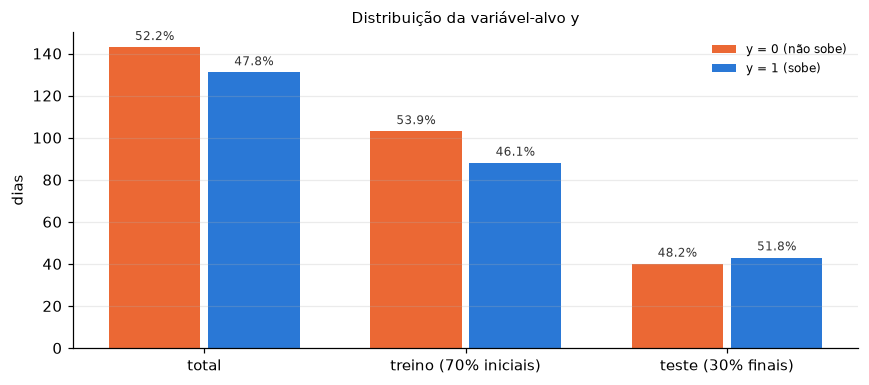

In [6]:
# Classes no total e nas duas partes do split temporal (o corte é formalizado na Etapa 4)
base_eda = completas.reset_index(drop=True)
corte_eda = int(len(base_eda) * FRACAO_TREINO)
partes = {"total": base_eda, "treino (70% iniciais)": base_eda.iloc[:corte_eda],
          "teste (30% finais)": base_eda.iloc[corte_eda:]}

linhas = []
for nome, parte in partes.items():
    n1 = int(parte["y"].sum())
    n0 = len(parte) - n1
    linhas.append({"conjunto": nome, "dias": len(parte),
                   "y=0 (não sobe)": n0, "y=1 (sobe)": n1,
                   "% y=0": n0 / len(parte), "% y=1": n1 / len(parte)})
dist_classes = pd.DataFrame(linhas).set_index("conjunto")
display(dist_classes.style.format({"% y=0": "{:.1%}", "% y=1": "{:.1%}"}))

# Gráfico: barras agrupadas (contagem), com o percentual escrito em cada barra
fig, ax = plt.subplots(figsize=(8, 3.6))
pos = np.arange(len(dist_classes))
larg = 0.38
for desloc, col, pct, cor, rot in [(-larg / 2, "y=0 (não sobe)", "% y=0", COR_2, "y = 0 (não sobe)"),
                                   (+larg / 2, "y=1 (sobe)", "% y=1", COR_1, "y = 1 (sobe)")]:
    barras = ax.bar(pos + desloc, dist_classes[col], width=larg - 0.03, color=cor, label=rot)
    for b, p in zip(barras, dist_classes[pct]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{p:.1%}",
                ha="center", va="bottom", fontsize=8, color="#333333")
ax.set_xticks(pos, dist_classes.index)
ax.set_ylabel("dias")
ax.set_title("Distribuição da variável-alvo y", fontsize=10)
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Interpretação.** As classes são **quase balanceadas**: 47,8% dos dias fecham em alta no total.
O treino tem 46,1% de altas e o teste 51,8% — a proporção **muda entre os períodos**, o que já
mostra por que a acurácia simples engana: o baseline "sempre alta" acertaria 51,8% no teste sem
aprender nada. Por isso a métrica principal do trabalho é a **acurácia balanceada** (média do
recall das duas classes), em que qualquer classificador constante vale exatamente 0,500.

## 2.4 Estatísticas descritivas dos atributos

In [7]:
display(base_eda[ATRIBUTOS].describe().T)

,count,mean,std,min,25%,50%,75%,max
ret_1d,274.0000,-0.0004,0.0331,-0.1483,-0.0191,-0.0008,0.0140,0.1127
ret_7d,274.0000,-0.0035,0.0896,-0.3349,-0.0442,-0.0087,0.0411,0.3013
ret_30d,274.0000,-0.0484,0.1653,-0.4605,-0.1366,-0.0260,0.0467,0.4799
ret_acum,274.0000,-0.2380,0.1745,-0.5151,-0.3757,-0.2832,-0.1215,0.3318
vol_7d,274.0000,0.0295,0.0140,0.0071,0.0191,0.0282,0.0363,0.0860
vol_30d,274.0000,0.0315,0.0095,0.0157,0.0244,0.0301,0.0365,0.0557
dist_mm_7,274.0000,-0.0028,0.0455,-0.2118,-0.0239,-0.0010,0.0184,0.1517
dist_mm_30,274.0000,-0.0214,0.1060,-0.3754,-0.0583,-0.0173,0.0292,0.3475
cruz_mm,274.0000,-0.1533,0.9900,-1.0000,-1.0000,-1.0000,1.0000,1.0000
drawdown,274.0000,-0.6225,0.0896,-0.7489,-0.6852,-0.6554,-0.5890,-0.4083


**Interpretação.** Os atributos vivem em **escalas muito diferentes**: `vol_30d` varia entre
~0,016 e ~0,056, enquanto `curtose_30` vai de −1,2 a 9,6 e `cruz_mm` de −1 a +1. Sem padronização,
modelos baseados em distância (KNN, SVM) seriam dominados pelos atributos de maior amplitude
(Etapa 3.4). O `drawdown` é sempre negativo (média −62%) e o `ret_acum` médio é −24%: o período
analisado é, no geral, de **queda** da Solana.

### Resumo da EDA aprofundada (`notebooks/eda_solana.ipynb`)

A EDA completa (7 visualizações, com interpretação) está em `notebooks/eda_solana.ipynb`. O achado
central: **a série tem estrutura na magnitude dos movimentos, mas quase nenhuma na direção.** A
autocorrelação dos retornos é indistinguível de ruído branco, enquanto a de |retornos| é
significativa (defasagens 1–3 e 5 — agrupamento de volatilidade); o volume tem correlação +0,003
com a direção e +0,600 com a magnitude. Isso antecipa que **classificar a direção do dia seguinte
deve ficar perto do acaso** — e é contra essa expectativa que os resultados serão lidos.

---
# Etapa 3 — Pré-processamento

## 3.1 Duplicatas, lacunas e sanidade dos valores

Aplicamos à base oficial a mesma sequência de `src/preprocess.py` (as funções são importadas de lá):
tipagem → remoção de duplicatas por (id, data) → índice diário contínuo (expõe dias ausentes) →
política de preenchimento (lacunas de até 3 dias são interpoladas e marcadas; lacunas maiores
ficam NaN) → sanidade (preço ≤ 0, capitalização ≤ 0, volume < 0) → regra de "ativos removidos".

In [8]:
# preprocess.carregar() lê Parquet: passamos o snapshot em memória, sem depender de data/processed
buffer = io.BytesIO()
bruto.to_parquet(buffer, index=False)
buffer.seek(0)
carregado = preprocess.carregar(buffer)                        # tipos + ordenação

sem_dup, n_duplicatas = preprocess.remover_duplicatas(carregado)

partes_limpas, removidos, diagnostico = [], [], []
for identificador, grupo in sem_dup.groupby("id", sort=True):  # um grupo por ativo (aqui, só a Solana)
    reindexado, diag = preprocess.reindexar_diario(grupo)       # índice diário contínuo
    preenchido, resumo = preprocess.preencher_lacunas(reindexado)
    limpo_ativo, sanidade = preprocess.sanidade_valores(preenchido)

    obs_reais = int((limpo_ativo["preco"].notna() & ~limpo_ativo["preenchido"]).sum())
    motivo = preprocess.avaliar_ativo(diag, obs_reais)          # None = ativo mantido
    diagnostico.append({**diag, **resumo, **sanidade, "obs_reais": obs_reais})
    if motivo:
        removidos.append({"id": identificador, "motivo": motivo})
        continue
    limpo_ativo["fonte"] = grupo["fonte"].iloc[0]
    limpo_ativo["coletado_em"] = grupo["coletado_em"].iloc[0]
    partes_limpas.append(limpo_ativo[preprocess.COLUNAS_SAIDA])

limpo = pd.concat(partes_limpas, ignore_index=True).sort_values(["id", "data"]).reset_index(drop=True)

d = diagnostico[0]
qualidade = pd.Series({
    "observações brutas": len(carregado),
    "duplicatas removidas (id, data)": n_duplicatas,
    "dias no período (índice contínuo)": d["dias_periodo"],
    "dias ausentes (lacunas)": d["dias_ausentes"],
    "blocos de lacuna": d["n_blocos"],
    "maior lacuna contígua (dias)": d["maior_lacuna"],
    "linhas preenchidas (lacunas <= 3 dias)": d["linhas_preenchidas"],
    "dias em lacunas longas (não preenchidos)": d["dias_lacuna_longa"],
    "preço <= 0": d["preco_nao_positivo"],
    "capitalização <= 0": d["capitalizacao_nao_positiva"],
    "volume < 0": d["volume_negativo"],
    "ativos removidos": len(removidos),
    "observações após a limpeza": len(limpo),
}, name="contagem").to_frame()
display(qualidade)

,contagem
observações brutas,365
"duplicatas removidas (id, data)",0
dias no período (índice contínuo),365
dias ausentes (lacunas),0
blocos de lacuna,0
maior lacuna contígua (dias),0
linhas preenchidas (lacunas <= 3 dias),0
dias em lacunas longas (não preenchidos),0
preço <= 0,0
capitalização <= 0,0


**Interpretação.** A base congelada está **íntegra**: 365 dias contínuos, nenhuma duplicata,
nenhuma lacuna (logo, nenhuma linha preenchida artificialmente), nenhum valor inválido, e a Solana
passa pela regra de "ativos removidos" (≥ 60 observações reais e ≤ 20% de lacunas). As etapas
continuam no código porque garantem a mesma qualidade se a base for recoletada da API, que pode
devolver dias faltando ou repetidos.

## 3.2 Tabela supervisionada e remoção das linhas incompletas

In [9]:
# Tabela final de treino/avaliação: atributos + y, sem as linhas incompletas
tabela = features.montar_tabela(limpo)
# Mesma tabela, mas preservando o último dia (sem rótulo) — usado só na Etapa 7
tabela_com_novo = features.montar_tabela(limpo, manter_sem_rotulo=True)

print(f"Tabela supervisionada: {tabela.shape[0]} linhas x {len(ATRIBUTOS)} atributos "
      f"({tabela['data'].min().date()} a {tabela['data'].max().date()})")
print(f"NaN restantes em X e y: {int(tabela[ATRIBUTOS + ['y']].isna().sum().sum())}")
print(f"Linhas removidas: {len(limpo) - len(tabela)} (90 de aquecimento + 1 sem rótulo)")

# Conferência: a tabela do notebook é a mesma gerada pelo pipeline (src/features.py)
arquivo_pipeline = RAIZ / "data" / "processed" / "atributos.parquet"
if arquivo_pipeline.exists():
    pipeline = pd.read_parquet(arquivo_pipeline)
    # compara os valores (a resolução interna da data muda na ida e volta pelo Parquet)
    mesmas_datas = np.array_equal(pipeline["data"].to_numpy().astype("datetime64[D]"),
                                  tabela["data"].to_numpy().astype("datetime64[D]"))
    mesmos_valores = pipeline[[*ATRIBUTOS, "y"]].equals(tabela[[*ATRIBUTOS, "y"]])
    print(f"Idêntica a data/processed/atributos.parquet: {mesmas_datas and mesmos_valores}")
display(tabela.head())

Tabela supervisionada: 274 linhas x 13 atributos (2025-11-30 a 2026-08-30)
NaN restantes em X e y: 0
Linhas removidas: 91 (90 de aquecimento + 1 sem rótulo)
Idêntica a data/processed/atributos.parquet: True


,id,data,preco,ret_1d,ret_7d,ret_30d,ret_acum,vol_7d,vol_30d,dist_mm_7,dist_mm_30,cruz_mm,drawdown,razao_vol_cap,assimetria_30,curtose_30,y_anterior,y
0,solana,2025-11-30,136.0233,-0.0100,0.0664,-0.2627,-0.3207,0.0296,0.0421,-0.0135,-0.0895,-1.0000,-0.4506,0.0357,-0.2204,0.3268,0,0
1,solana,2025-12-01,133.8264,-0.0162,0.0249,-0.2850,-0.3211,0.0303,0.0419,-0.0326,-0.0935,-1.0000,-0.4595,0.0462,-0.1525,0.3801,0,0
2,solana,2025-12-02,126.6739,-0.0534,-0.0844,-0.3201,-0.3942,0.0254,0.0426,-0.0732,-0.1302,-1.0000,-0.4884,0.0941,-0.0604,0.1598,0,1
3,solana,2025-12-03,138.6722,0.0947,-0.0019,-0.2611,-0.3420,0.0481,0.0467,0.0149,-0.0370,-1.0000,-0.4399,0.0888,0.1898,0.1388,1,1
4,solana,2025-12-04,144.8290,0.0444,0.0127,-0.1269,-0.2848,0.0499,0.0431,0.0579,0.0107,-1.0000,-0.4151,0.0798,0.4786,-0.4357,1,0


**Por que remover (e não imputar) as linhas com NaN?** Os NaN do início não são "dados perdidos":
são dias em que **o passado necessário ainda não existe** (ex.: não há retorno de 90 dias antes do
90º dia). Preencher com zero ou com a média inventaria um histórico que não aconteceu — e a média
calculada sobre a série inteira ainda **vazaria informação do futuro** para o passado. Descartar
os 90 dias de aquecimento custa linhas, mas mantém cada exemplo honesto. A linha sem rótulo
(último dia) também sai do treino, porque não há gabarito para ela.

## 3.3 Conversão texto → número

As colunas de texto (`id`, `simbolo`, `nome`, `fonte`) são **constantes** — com um único ativo,
todas as linhas têm o mesmo valor. Uma coluna constante não ajuda a separar classes, então elas
são simplesmente **descartadas de X** (não precisam de codificação). `coletado_em` é metadado e
`data` é o índice temporal; nenhuma das duas entra como atributo. O alvo booleano
(`preço amanhã > preço hoje`) é convertido para inteiro 0/1.

Se o projeto tivesse **vários ativos**, `id`/`simbolo` passariam a variar e precisariam virar
números por **one-hot encoding** (`OneHotEncoder` / `pd.get_dummies`) — nunca por códigos 0, 1, 2…,
que criariam uma ordem falsa entre os ativos.

In [10]:
texto = ["id", "simbolo", "nome", "fonte"]
print("Valores distintos nas colunas de texto:", {c: limpo[c].nunique() for c in texto})
print("Colunas usadas em X (todas numéricas):", list(tabela[ATRIBUTOS].dtypes.astype(str).unique()))
print("Tipo do alvo y:", tabela["y"].dtype, "| valores:", sorted(tabela["y"].unique()))

Valores distintos nas colunas de texto: {'id': 1, 'simbolo': 1, 'nome': 1, 'fonte': 1}
Colunas usadas em X (todas numéricas): ['float64']
Tipo do alvo y: int64 | valores: [np.int64(0), np.int64(1)]


## 3.4 Escala (padronização)

Usamos `StandardScaler` (cada atributo → média 0, desvio 1) **dentro de um `Pipeline`**, junto
com o classificador:

- **Por que KNN e SVM precisam:** ambos medem **distância** entre exemplos. Sem escala, um atributo
  que varia de −1 a 10 (`curtose_30`) domina outro que varia de 0,016 a 0,056 (`vol_30d`), e a
  distância passa a refletir só o primeiro. O Perceptron também se beneficia (o gradiente fica bem
  condicionado). Árvore e Naive Bayes não dependem da escala, mas a mantemos para que todos os
  modelos recebam exatamente a mesma entrada.
- **Por que dentro do Pipeline evita vazamento:** ao chamar `pipeline.fit(X_treino, y_treino)`, a
  média e o desvio do scaler são calculados **só com o treino**; no teste o scaler apenas
  *aplica* esses números. Se padronizássemos a tabela inteira antes do split, a média e o desvio
  incluiriam os dias de teste — o modelo receberia, de forma escondida, informação do futuro.
  O mesmo vale para cada partição do `TimeSeriesSplit` (Etapa 5). A verificação está na seção 5.4.

---
# Etapa 4 — Divisão dos dados

## 4.1 Separação de X e y

In [11]:
X = tabela[ATRIBUTOS].to_numpy()     # 13 atributos (só passado até t)
y = tabela["y"].to_numpy()           # alvo: 1 se o preço de t+1 > preço de t
print(f"X: {X.shape}   y: {y.shape}   proporção de y=1: {y.mean():.1%}")

X: (274, 13)   y: (274,)   proporção de y=1: 47.8%


## 4.2 Split principal: cronológico 70/30, sem embaralhar

In [12]:
# Os 70% iniciais (mais antigos) são treino; os 30% finais (mais recentes) são teste.
corte = int(len(tabela) * FRACAO_TREINO)
treino = tabela.iloc[:corte].copy()
teste = tabela.iloc[corte:].copy()

X_treino, y_treino = treino[ATRIBUTOS].to_numpy(), treino["y"].to_numpy()
X_teste, y_teste = teste[ATRIBUTOS].to_numpy(), teste["y"].to_numpy()

assert treino["data"].max() < teste["data"].min()   # nenhum dia de teste antes do fim do treino
print(f"Treino: {len(treino)} dias ({treino['data'].min().date()} a {treino['data'].max().date()}) "
      f"| y=1: {y_treino.mean():.1%}")
print(f"Teste : {len(teste)} dias ({teste['data'].min().date()} a {teste['data'].max().date()}) "
      f"| y=1: {y_teste.mean():.1%}")

Treino: 191 dias (2025-11-30 a 2026-06-08) | y=1: 46.1%
Teste : 83 dias (2026-06-09 a 2026-08-30) | y=1: 51.8%


**Por que não embaralhar?** Em série temporal, a avaliação precisa simular o uso real: o modelo é
treinado com o passado e aplicado a dias que ainda não viu. Embaralhar quebra isso de duas formas:

1. **Dias vizinhos caem dos dois lados.** Os atributos usam janelas móveis sobrepostas — o
   `vol_30d` de hoje e o de amanhã compartilham 29 dos 30 retornos. Com embaralhamento, quase todo
   dia de teste tem o dia anterior ou o seguinte no treino, com atributos quase idênticos: o modelo
   é testado em exemplos que ele praticamente já viu.
2. **O modelo "vê o futuro".** Treinar com dias de setembro para prever dias de junho usa
   informação que não existiria no momento da previsão. Pior: o rótulo de um dia de teste
   ($P_{t+1} > P_t$) está literalmente contido no atributo `ret_1d` do dia seguinte, que pode estar
   no treino.

Por isso o resultado **oficial** do trabalho usa o split cronológico acima (o mesmo de
`src/classification.py`).

## 4.3 Experimento de contraste: split embaralhado

In [13]:
# Split aleatório estratificado (o que o plano de atividades pede como comparação).
# Dividimos os ÍNDICES para saber quais datas foram para cada lado.
idx_tr_emb, idx_te_emb = train_test_split(
    np.arange(len(tabela)), test_size=0.2, shuffle=True, stratify=y, random_state=SEMENTE)
X_tr_emb, y_tr_emb = X[idx_tr_emb], y[idx_tr_emb]
X_te_emb, y_te_emb = X[idx_te_emb], y[idx_te_emb]

# Quantos dias de teste têm o dia anterior OU o seguinte dentro do treino?
no_treino = set(idx_tr_emb)
com_vizinho = sum((i - 1 in no_treino) or (i + 1 in no_treino) for i in idx_te_emb)
print(f"Treino embaralhado: {len(idx_tr_emb)} dias | teste embaralhado: {len(idx_te_emb)} dias "
      f"| y=1 no teste: {y_te_emb.mean():.1%}")
print(f"Dias de teste com um vizinho imediato (t-1 ou t+1) no treino: {com_vizinho} de {len(idx_te_emb)}")
print(f"Datas do teste embaralhado vão de {tabela['data'].iloc[idx_te_emb].min().date()} "
      f"a {tabela['data'].iloc[idx_te_emb].max().date()} (espalhadas pelo ano inteiro)")

Treino embaralhado: 219 dias | teste embaralhado: 55 dias | y=1 no teste: 47.3%
Dias de teste com um vizinho imediato (t-1 ou t+1) no treino: 54 de 55
Datas do teste embaralhado vão de 2025-12-01 a 2026-08-30 (espalhadas pelo ano inteiro)


**Interpretação.** Com `shuffle=True`, **54 dos 55 dias de teste têm um vizinho imediato no
treino** — exatamente a sobreposição descrita acima. A comparação de desempenho entre os dois
splits precisa dos modelos (Etapa 5) e das métricas (Etapa 6), então é executada na **seção 6.5**,
com os mesmos modelos e hiperparâmetros. O resultado oficial continua sendo o do split temporal.

---
# Etapa 5 — Treinamento

## 5.1 Baselines

Antes de qualquer modelo, medimos referências ingênuas. Um modelo só tem valor se superá-las.

In [14]:
def prever_baselines(df_treino: pd.DataFrame, df_alvo: pd.DataFrame) -> dict[str, np.ndarray]:
    # Previsões dos três baselines para as linhas de df_alvo (lógica de src/classification.py)
    n = len(df_alvo)
    # 1) sempre alta: prevê 1 em todos os dias
    sempre_alta = np.ones(n, dtype=int)
    # 2) classe majoritária: prevê sempre a classe mais frequente NO TREINO
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(df_treino[ATRIBUTOS], df_treino["y"])
    majoritaria = dummy.predict(df_alvo[ATRIBUTOS]).astype(int)
    # 3) persistência: repete o resultado de ontem (y de t-1, já conhecido em t)
    persistencia = (df_alvo["y_anterior"].astype("Float64")
                    .fillna(float(majoritaria[0]) if n else 0.0).astype(int).to_numpy())
    return {"Baseline: sempre alta": sempre_alta,
            "Baseline: classe majoritária (treino)": majoritaria,
            "Baseline: persistência": persistencia}

## 5.2 Modelos (cada um num Pipeline com StandardScaler)

In [15]:
def construir_modelos() -> dict[str, Pipeline]:
    # Devolve Pipelines NOVOS (sem nada ajustado) a cada chamada
    return {
        # KNN: classifica pelo voto dos 15 dias mais parecidos no espaço padronizado
        "KNN": Pipeline([("escala", StandardScaler()),
                         ("modelo", KNeighborsClassifier(n_neighbors=K_VIZINHOS))]),
        # SVM com kernel RBF: fronteira não linear de margem máxima
        "SVM (RBF)": Pipeline([("escala", StandardScaler()),
                               ("modelo", SVC(kernel="rbf", random_state=SEMENTE))]),
        # Árvore rasa (3 níveis): regras do tipo "se atributo > limiar"; rasa para não decorar o treino
        "Árvore de decisão": Pipeline([("escala", StandardScaler()),
                                       ("modelo", DecisionTreeClassifier(max_depth=PROFUNDIDADE_ARVORE,
                                                                         random_state=SEMENTE))]),
        # Naive Bayes gaussiano: probabilidades supondo atributos independentes e normais por classe
        "Naive Bayes": Pipeline([("escala", StandardScaler()),
                                 ("modelo", GaussianNB())]),
        # Perceptron: classificador linear (soma ponderada dos atributos > 0), ajustado por correção de erros
        "Perceptron": Pipeline([("escala", StandardScaler()),
                                ("modelo", Perceptron(random_state=SEMENTE))]),
    }

print("Modelos:", list(construir_modelos()))

Modelos: ['KNN', 'SVM (RBF)', 'Árvore de decisão', 'Naive Bayes', 'Perceptron']


## 5.3 Seleção do melhor modelo por `TimeSeriesSplit` — só no treino

O `TimeSeriesSplit` divide o **treino** em 5 partições em ordem cronológica: em cada uma, o modelo
treina com um trecho inicial e valida no trecho imediatamente seguinte (walk-forward). Modelos e
baselines são avaliados nas **mesmas** partições. **O conjunto de teste não participa da escolha.**

In [16]:
particoes = list(TimeSeriesSplit(n_splits=N_SPLITS).split(X_treino))
for i, (a, b) in enumerate(particoes, 1):
    print(f"  partição {i}: treina em {len(a):3d} dias -> valida em {len(b)} dias "
          f"({treino['data'].iloc[b[0]].date()} a {treino['data'].iloc[b[-1]].date()})")

# nome -> (tipo, [acurácias balanceadas por partição], [F1 por partição])
placar: dict[str, tuple[str, list[float], list[float]]] = {}

def registrar(nome: str, tipo: str, y_val: np.ndarray, previsto: np.ndarray) -> None:
    _, accs, f1s = placar.setdefault(nome, (tipo, [], []))
    accs.append(balanced_accuracy_score(y_val, previsto))
    f1s.append(f1_score(y_val, previsto, zero_division=0))

for idx_tr, idx_val in particoes:
    fold_treino, fold_val = treino.iloc[idx_tr], treino.iloc[idx_val]
    for nome, previsto in prever_baselines(fold_treino, fold_val).items():
        registrar(nome, "baseline", y_treino[idx_val], previsto)
    for nome, modelo in construir_modelos().items():          # Pipeline novo em cada partição
        modelo.fit(X_treino[idx_tr], y_treino[idx_tr])         # escala ajustada só no trecho de treino
        registrar(nome, "modelo", y_treino[idx_val], modelo.predict(X_treino[idx_val]))

walk_forward = pd.DataFrame([
    {"modelo": nome, "tipo": tipo,
     "acc. balanceada (média)": np.mean(accs), "acc. balanceada (dp)": np.std(accs),
     "F1 (média)": np.mean(f1s), "F1 (dp)": np.std(f1s)}
    for nome, (tipo, accs, f1s) in placar.items()
]).sort_values("acc. balanceada (média)", ascending=False).reset_index(drop=True)

# Critério de seleção: maior acurácia balanceada média entre os MODELOS (baselines não concorrem)
MELHOR = str(walk_forward.loc[walk_forward["tipo"] == "modelo", "modelo"].iloc[0])

exibir = walk_forward.assign(**{
    "acc. balanceada": walk_forward["acc. balanceada (média)"].map("{:.3f}".format)
                       + " ± " + walk_forward["acc. balanceada (dp)"].map("{:.3f}".format),
    "F1": walk_forward["F1 (média)"].map("{:.3f}".format)
          + " ± " + walk_forward["F1 (dp)"].map("{:.3f}".format),
})[["modelo", "tipo", "acc. balanceada", "F1"]]
display(exibir)
print(f"Modelo selecionado (sem olhar o teste): {MELHOR}")

  partição 1: treina em  36 dias -> valida em 31 dias (2026-01-05 a 2026-02-04)
  partição 2: treina em  67 dias -> valida em 31 dias (2026-02-05 a 2026-03-07)
  partição 3: treina em  98 dias -> valida em 31 dias (2026-03-08 a 2026-04-07)
  partição 4: treina em 129 dias -> valida em 31 dias (2026-04-08 a 2026-05-08)
  partição 5: treina em 160 dias -> valida em 31 dias (2026-05-09 a 2026-06-08)


,modelo,tipo,acc. balanceada,F1
0,Perceptron,modelo,0.519 ± 0.083,0.367 ± 0.141
1,Baseline: persistência,baseline,0.517 ± 0.067,0.482 ± 0.083
2,Baseline: classe majoritária (treino),baseline,0.500 ± 0.000,0.000 ± 0.000
3,Baseline: sempre alta,baseline,0.500 ± 0.000,0.623 ± 0.089
4,Árvore de decisão,modelo,0.495 ± 0.032,0.497 ± 0.044
5,SVM (RBF),modelo,0.480 ± 0.023,0.293 ± 0.255
6,KNN,modelo,0.478 ± 0.046,0.252 ± 0.242
7,Naive Bayes,modelo,0.462 ± 0.050,0.151 ± 0.208


Modelo selecionado (sem olhar o teste): Perceptron


**Interpretação.** O **Perceptron** tem a maior acurácia balanceada média no walk-forward
(0,519 ± 0,083) e é o modelo selecionado. Mas a margem é mínima: ele empata, na prática, com o
baseline de persistência (0,517), e o desvio entre partições (±0,08) é bem maior que a diferença
entre os modelos. Árvore, SVM, KNN e Naive Bayes ficam **abaixo** de 0,5 nesta validação. Já é um
sinal coerente com a EDA: não há um modelo claramente superior, porque há pouco sinal de direção
a aprender.

## 5.4 Treinamento final no treino inteiro

In [17]:
# Cada modelo é reajustado no treino completo (191 dias) — é este ajuste que vai ao teste na Etapa 6
modelos_treinados = {}
for nome, modelo in construir_modelos().items():
    modelo.fit(X_treino, y_treino)
    modelos_treinados[nome] = modelo

# Verificação do não-vazamento da escala: o scaler aprendeu a média do TREINO, não da tabela inteira
escala = modelos_treinados[MELHOR].named_steps["escala"]
print("média do scaler == média do treino:", np.allclose(escala.mean_, X_treino.mean(axis=0)))
print("média do scaler == média da tabela inteira:", np.allclose(escala.mean_, X.mean(axis=0)))

média do scaler == média do treino: True
média do scaler == média da tabela inteira: False


---
# Etapa 6 — Avaliação e comparação

## 6.1 Métricas no teste (modelos e baselines)

Cada modelo, já treinado nos 191 dias de treino, é avaliado **uma única vez** nos 83 dias finais.

In [18]:
def avaliar(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    # Métricas de classificação binária (classe positiva = 1, "sobe")
    return {
        "acurácia": accuracy_score(y_true, y_pred),
        "acc. balanceada": balanced_accuracy_score(y_true, y_pred),
        "precisão": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

previsoes_teste = {nome: m.predict(X_teste) for nome, m in modelos_treinados.items()}
previsoes_base = prever_baselines(treino, teste)

resultados = pd.DataFrame(
    [{"modelo": n, "tipo": "baseline", **avaliar(y_teste, p)} for n, p in previsoes_base.items()]
    + [{"modelo": n, "tipo": "modelo", **avaliar(y_teste, p)} for n, p in previsoes_teste.items()]
)
melhor_baseline = resultados.loc[resultados["tipo"] == "baseline", "acc. balanceada"].max()
resultados["Δ vs melhor baseline"] = resultados["acc. balanceada"] - melhor_baseline
resultados["selecionado"] = np.where(resultados["modelo"] == MELHOR, "◀ selecionado na Etapa 5", "")
resultados = resultados.sort_values("acc. balanceada", ascending=False).reset_index(drop=True)
display(resultados.style.format({c: "{:.3f}" for c in
        ["acurácia", "acc. balanceada", "precisão", "recall", "F1"]}
        | {"Δ vs melhor baseline": "{:+.3f}"}))

,modelo,tipo,acurácia,acc. balanceada,precisão,recall,F1,Δ vs melhor baseline,selecionado
0,Perceptron,modelo,0.578,0.575,0.580,0.674,0.624,+0.075,◀ selecionado na Etapa 5
1,Baseline: sempre alta,baseline,0.518,0.500,0.518,1.000,0.683,+0.000,
2,Baseline: classe majoritária (treino),baseline,0.482,0.500,0.000,0.000,0.000,+0.000,
3,SVM (RBF),modelo,0.494,0.499,0.516,0.372,0.432,-0.001,
4,Árvore de decisão,modelo,0.482,0.483,0.500,0.465,0.482,-0.017,
5,Baseline: persistência,baseline,0.482,0.481,0.500,0.512,0.506,-0.019,
6,KNN,modelo,0.458,0.458,0.476,0.465,0.471,-0.042,
7,Naive Bayes,modelo,0.410,0.419,0.350,0.163,0.222,-0.081,


**Interpretação.** No teste, o **Perceptron** obtém a maior acurácia balanceada (**0,575**, +0,075
sobre o melhor baseline) e o maior F1 entre os modelos (0,624). Os demais modelos ficam **no nível
ou abaixo** dos baselines (SVM 0,499; árvore 0,483; KNN 0,458; Naive Bayes 0,419). Repare como o
F1 sozinho engana: o "sempre alta" tem o **maior F1 da tabela (0,683)** sem aprender nada, porque
recall = 1 infla o F1 quando a classe positiva é ~metade dos dias. É por isso que o critério
principal é a acurácia balanceada.

## 6.2 Matrizes de confusão — todos os modelos e baselines

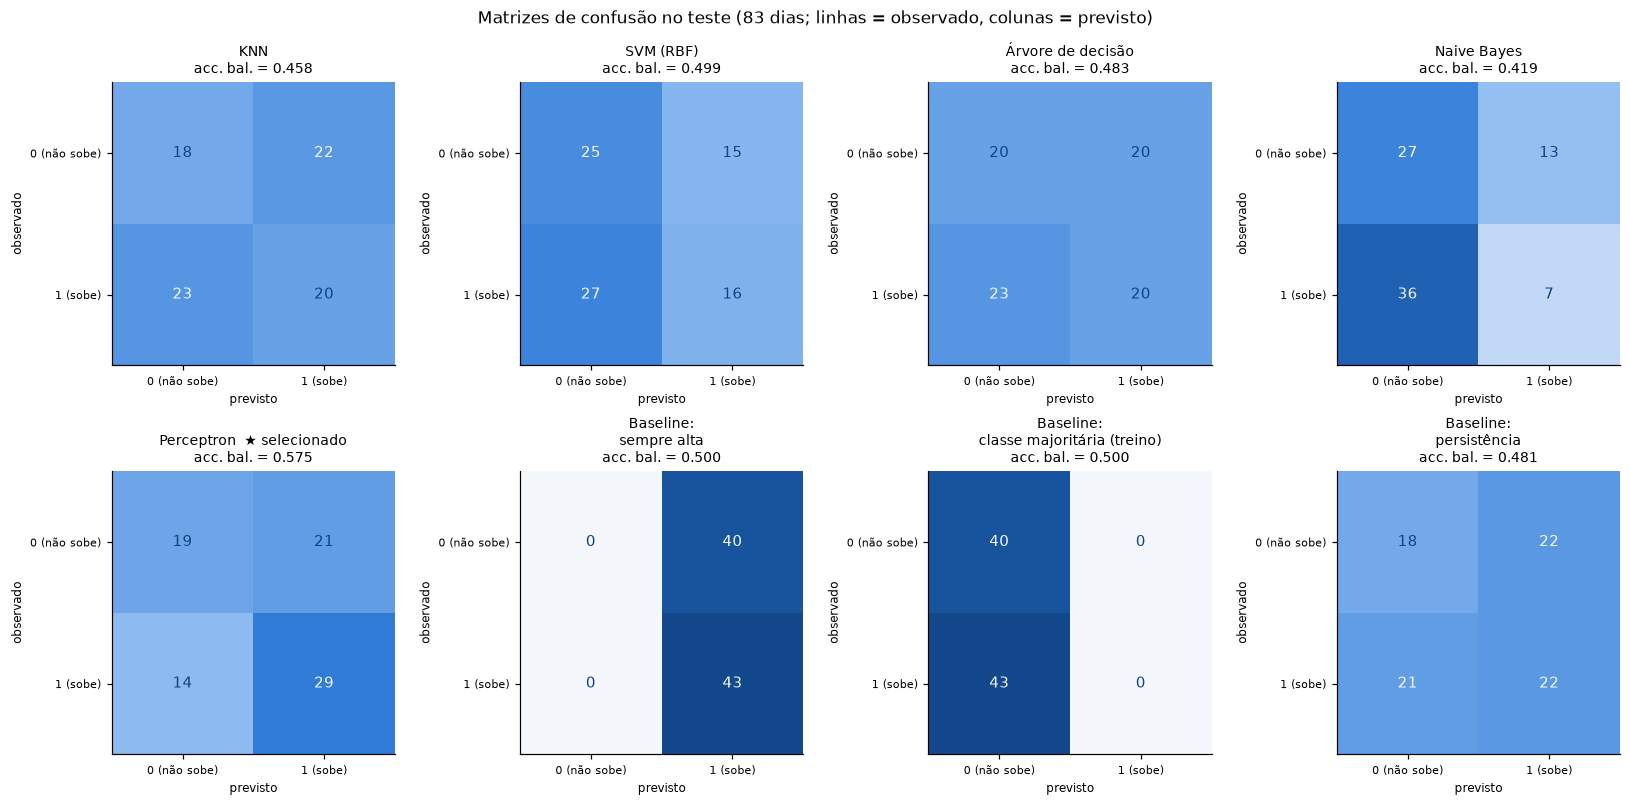

In [19]:
ordem = list(previsoes_teste) + list(previsoes_base)
todas = {**previsoes_teste, **previsoes_base}

fig, eixos = plt.subplots(2, 4, figsize=(15, 7.4))
for ax, nome in zip(eixos.ravel(), ordem):
    matriz = confusion_matrix(y_teste, todas[nome], labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=["0 (não sobe)", "1 (sobe)"]).plot(
        ax=ax, cmap=RAMPA_AZUL, colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": 45})   # mesma escala de cor em todos os painéis
    acc_bal = balanced_accuracy_score(y_teste, todas[nome])
    marca = "  ★ selecionado" if nome == MELHOR else ""
    titulo = nome.replace("Baseline: ", "Baseline:\n")   # quebra os nomes longos em 2 linhas
    ax.set_title(f"{titulo}{marca}\nacc. bal. = {acc_bal:.3f}", fontsize=9)
    ax.set_xlabel("previsto", fontsize=8)
    ax.set_ylabel("observado", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(False)
fig.suptitle("Matrizes de confusão no teste (83 dias; linhas = observado, colunas = previsto)",
             fontsize=11)
fig.tight_layout()
plt.show()

**Interpretação.** As matrizes mostram **como** cada modelo erra:

- **Perceptron** (selecionado): acerta 29 das 43 altas e 19 dos 40 dias de baixa — 48 acertos.
  É o único que acerta bem as altas sem chutar "alta" o tempo todo.
- **Naive Bayes** quase só prevê baixa (63 de 83 dias) e erra 36 das 43 altas.
- **SVM** e **árvore** ficam espalhados de forma quase uniforme — perto de uma moeda.
- Os baselines constantes ocupam **uma coluna só** ("sempre alta" e "classe majoritária", que no
  treino era 0), o que explica a acurácia balanceada exata de 0,500.

## 6.3 Melhor modelo e critério

**Melhor modelo: Perceptron.**

- **Critério:** maior **acurácia balanceada média** no `TimeSeriesSplit` (5 partições) **dentro do
  treino** — a escolha foi feita na Etapa 5, **antes** de olhar o teste. A acurácia balanceada foi
  escolhida por ser insensível à proporção de classes (um classificador constante vale sempre 0,500).
- **Confirmação no teste:** o mesmo Perceptron também tem a maior acurácia balanceada nos 83 dias
  de teste (0,575). A seleção não foi trocada depois de ver o teste — se tivesse sido, o número do
  teste deixaria de ser uma estimativa honesta.

## 6.4 O resultado é distinguível do acaso? (teste binomial)

In [20]:
previsto_melhor = previsoes_teste[MELHOR]
n_dias = len(y_teste)
acertos = int((previsto_melhor == y_teste).sum())
# H0: o modelo acerta cada dia com probabilidade 0,5 (cara-ou-coroa); teste unilateral
p_valor = binomtest(acertos, n_dias, 0.5, alternative="greater").pvalue
margem = 1.96 * np.sqrt(0.25 / n_dias)          # meia-largura do IC 95% de uma proporção ~50%
desvios = (acertos - n_dias / 2) / np.sqrt(n_dias * 0.25)
acertos_para_5pct = min(k for k in range(n_dias + 1)
                        if binomtest(k, n_dias, 0.5, alternative="greater").pvalue < 0.05)

print(f"{MELHOR}: {acertos} acertos em {n_dias} dias = {acertos / n_dias:.1%}")
print(f"Teste binomial vs 50%: p = {p_valor:.3f}  ({desvios:.1f} desvios-padrão acima de 50%)")
print(f"IC 95% de uma acurácia perto de 50% com {n_dias} dias: ±{margem:.1%}")
print(f"Seriam necessários {acertos_para_5pct} acertos ({acertos_para_5pct / n_dias:.1%}) para p < 0,05")
print(f"Referência: 'sempre alta' acerta {int(y_teste.sum())}/{n_dias} = {y_teste.mean():.1%}")

Perceptron: 48 acertos em 83 dias = 57.8%
Teste binomial vs 50%: p = 0.094  (1.4 desvios-padrão acima de 50%)
IC 95% de uma acurácia perto de 50% com 83 dias: ±10.8%
Seriam necessários 50 acertos (60.2%) para p < 0,05
Referência: 'sempre alta' acerta 43/83 = 51.8%


**Discussão honesta.** O Perceptron acertou 48 de 83 dias (57,8%). Uma moeda honesta produziria
esse número ou mais com probabilidade **p ≈ 0,09** — o resultado está a **1,4 desvio-padrão** do
acaso e **não é estatisticamente significativo** (seriam necessários 50 acertos para p < 0,05).
Com só 83 dias de teste, a margem do IC 95% é de ±10,8 pontos: diferenças de alguns pontos
percentuais entre modelos cabem inteiramente no ruído. Além disso, o próprio walk-forward do
treino deu ao Perceptron 0,519 ± 0,083 — o 0,575 do teste está dentro de um desvio disso.

Isso é **coerente com a EDA**: a direção diária da Solana se comporta como ruído, e o que a série
tem de previsível está na magnitude (volatilidade), não no sinal. O valor deste trabalho está no
**protocolo** — atributos só com passado (verificado em `tests/test_vazamento.py`), split
cronológico, escala dentro do Pipeline, baselines medidos nas mesmas condições e seleção sem olhar
o teste — e não em um número de acurácia alto.

## 6.5 Contraste: split embaralhado × split temporal (experimento da Etapa 4)

Os **mesmos** modelos e hiperparâmetros, agora treinados e avaliados no split aleatório
estratificado da seção 4.3 (80/20, `random_state=42`).

,acc. bal. — temporal (oficial),acc. bal. — embaralhado,diferença,F1 — temporal,F1 — embaralhado,embaralhado — média de 30 sementes
modelo,,,,,,
KNN,0.458,0.603,+0.145,0.471,0.607,0.499 ± 0.053
SVM (RBF),0.499,0.545,+0.047,0.432,0.528,0.500 ± 0.065
Árvore de decisão,0.483,0.584,+0.101,0.482,0.582,0.513 ± 0.058
Naive Bayes,0.419,0.487,+0.069,0.222,0.440,0.486 ± 0.059
Perceptron,0.575,0.553,-0.022,0.624,0.590,0.540 ± 0.048


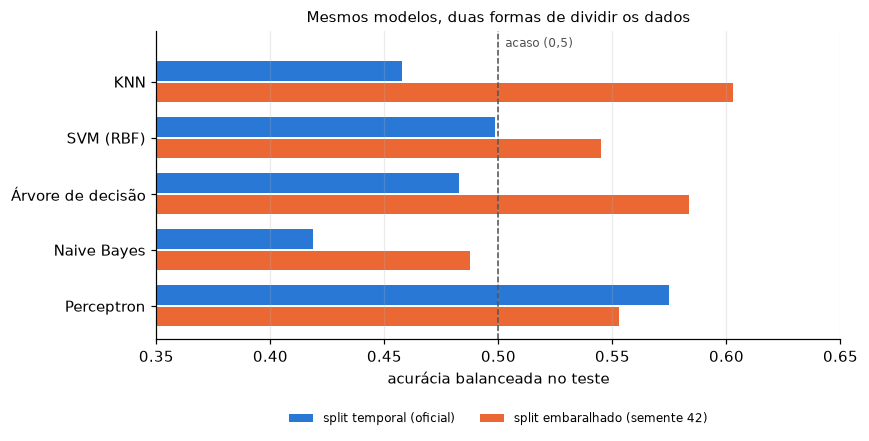

In [21]:
# Mesmos modelos, treinados no split embaralhado da seção 4.3
contraste = []
for nome, modelo in construir_modelos().items():
    modelo.fit(X_tr_emb, y_tr_emb)
    m_emb = avaliar(y_te_emb, modelo.predict(X_te_emb))
    m_tmp = avaliar(y_teste, previsoes_teste[nome])
    contraste.append({"modelo": nome,
                      "acc. bal. — temporal (oficial)": m_tmp["acc. balanceada"],
                      "acc. bal. — embaralhado": m_emb["acc. balanceada"],
                      "diferença": m_emb["acc. balanceada"] - m_tmp["acc. balanceada"],
                      "F1 — temporal": m_tmp["F1"], "F1 — embaralhado": m_emb["F1"]})
contraste = pd.DataFrame(contraste).set_index("modelo")

# Um único sorteio pode ser sorte: repetimos o split embaralhado com 30 sementes diferentes
repeticoes = {nome: [] for nome in construir_modelos()}
for semente in range(30):
    a, b = train_test_split(np.arange(len(tabela)), test_size=0.2, shuffle=True,
                            stratify=y, random_state=semente)
    for nome, modelo in construir_modelos().items():
        modelo.fit(X[a], y[a])
        repeticoes[nome].append(balanced_accuracy_score(y[b], modelo.predict(X[b])))
contraste["embaralhado — média de 30 sementes"] = [
    f"{np.mean(v):.3f} ± {np.std(v):.3f}" for v in repeticoes.values()]

display(contraste.style.format({c: "{:.3f}" for c in contraste.columns[:5]}
                               | {"diferença": "{:+.3f}"}))

# Gráfico: acurácia balanceada nos dois splits, por modelo
fig, ax = plt.subplots(figsize=(8, 4.2))
pos = np.arange(len(contraste))
larg = 0.38
ax.barh(pos - larg / 2, contraste["acc. bal. — temporal (oficial)"], height=larg - 0.03,
        color=COR_1, label="split temporal (oficial)")
ax.barh(pos + larg / 2, contraste["acc. bal. — embaralhado"], height=larg - 0.03,
        color=COR_2, label="split embaralhado (semente 42)")
ax.axvline(0.5, color="#52514e", linewidth=1, linestyle="--")
ax.set_yticks(pos, contraste.index)
ax.set_ylim(len(contraste) - 0.4, -0.9)          # eixo invertido, com folga no topo para o rótulo
ax.text(0.503, -0.62, "acaso (0,5)", fontsize=8, color="#52514e")
ax.set_xlim(0.35, 0.65)
ax.set_xlabel("acurácia balanceada no teste")
ax.set_title("Mesmos modelos, duas formas de dividir os dados", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Interpretação.** Com o split embaralhado (semente 42), o quadro muda: **KNN salta de 0,458
para 0,603** e a **árvore de 0,483 para 0,584** — passariam a parecer os melhores modelos, e o
ranking inteiro se inverteria. Mas, ao repetir o embaralhamento com 30 sementes, a média de todos
os modelos volta para perto de **0,50** (o Perceptron fica em ~0,54). Ou seja:

- o salto do KNN não é capacidade preditiva: é **efeito do sorteio**, e um único split aleatório não
  revela isso;
- o split embaralhado mistura todos os regimes do ano no treino e no teste e coloca 54 de 55 dias de
  teste ao lado de um vizinho do treino — avalia o modelo numa situação que **não existe na prática**
  (ninguém treina com setembro para prever junho);
- com um alvo quase aleatório como a direção diária, o vazamento entre vizinhos tem pouco sinal para
  explorar; com um alvo persistente (como a volatilidade do Apêndice), o mesmo embaralhamento
  inflaria muito mais os resultados.

**O resultado oficial do trabalho é o do split temporal (seções 6.1–6.4).** O embaralhado fica
registrado apenas como contraste metodológico.

---
# Etapa 7 — Uso do modelo

Usamos **o mesmo modelo selecionado nas Etapas 5/6** (Perceptron) — sem reescolher. Para usá-lo de
verdade, ele é **reajustado com todos os 274 dias rotulados** (treino + teste: agora o teste já
cumpriu seu papel de avaliação, e descartar os dias mais recentes pioraria o modelo).

O **item novo** é o último dia da base, **2026-08-31**: os atributos dele estão completos (só usam
o passado), mas ele **não tem rótulo** — o preço de 2026-09-01 não está na base. Ele nunca foi
visto em nenhum treino. A classificação dele é a estimativa do modelo para a direção de
**2026-09-01**.

In [22]:
# Item novo: a linha sem rótulo (último dia), que ficou fora de toda a modelagem
item_novo = tabela_com_novo[tabela_com_novo["y"].isna()].reset_index(drop=True)
assert len(item_novo) == 1 and item_novo["data"].iloc[0] not in set(tabela["data"])
data_base = item_novo["data"].iloc[0]
data_alvo = data_base + pd.Timedelta(days=1)
preco_base = float(item_novo["preco"].iloc[0])

# Valores dos atributos do item novo e onde eles caem no histórico (percentil nos 274 dias)
valores = item_novo[ATRIBUTOS].T.rename(columns={0: "valor em " + str(data_base.date())})
valores["percentil no histórico"] = [(tabela[c] <= item_novo[c].iloc[0]).mean() for c in ATRIBUTOS]
print(f"Item novo: {data_base.date()} | preço {preco_base:.2f} USD | rótulo: desconhecido")
display(valores.style.format({valores.columns[0]: "{:.4f}", "percentil no histórico": "{:.0%}"}))

Item novo: 2026-08-31 | preço 101.68 USD | rótulo: desconhecido


,valor em 2026-08-31,percentil no histórico
ret_1d,-0.0370,10%
ret_7d,0.0658,83%
ret_30d,0.3968,99%
ret_acum,0.2529,99%
vol_7d,0.0465,90%
vol_30d,0.0323,62%
dist_mm_7,-0.0087,43%
dist_mm_30,0.2100,97%
cruz_mm,1.0000,100%
drawdown,-0.5893,75%


In [23]:
# Reajusta o MESMO modelo (mesmo Pipeline e hiperparâmetros) com todos os dias rotulados
modelo_final = construir_modelos()[MELHOR]
modelo_final.fit(X, y)

X_novo = item_novo[ATRIBUTOS].to_numpy()
classe = int(modelo_final.predict(X_novo)[0])
rotulo = {1: "ALTA (preço de amanhã acima do de hoje)", 0: "BAIXA/ESTÁVEL (não acima do de hoje)"}

print(f"Modelo: {MELHOR}, reajustado com {len(X)} dias ({tabela['data'].min().date()} a "
      f"{tabela['data'].max().date()})")
print(f"Classificação para {data_alvo.date()}: classe {classe} -> {rotulo[classe]}")

if hasattr(modelo_final, "predict_proba"):
    print("predict_proba [P(0), P(1)]:", modelo_final.predict_proba(X_novo)[0].round(3))
if hasattr(modelo_final, "decision_function"):
    score = float(modelo_final.decision_function(X_novo)[0])
    print(f"decision_function = {score:+.3f}  (> 0 => classe 1; o Perceptron não estima probabilidades)")

# Perceptron é linear: score = intercepto + Σ peso_i × atributo_padronizado_i.
# A tabela mostra quais atributos empurraram a decisão (positivo = a favor da alta).
if MELHOR == "Perceptron":
    z = modelo_final.named_steps["escala"].transform(X_novo)[0]
    pesos = modelo_final.named_steps["modelo"].coef_[0]
    contrib = pd.DataFrame({"atributo padronizado": z, "peso": pesos, "contribuição": z * pesos},
                           index=ATRIBUTOS).sort_values("contribuição", key=np.abs, ascending=False)
    print(f"intercepto = {modelo_final.named_steps['modelo'].intercept_[0]:+.3f}")
    display(contrib.head(6))

# Para contexto: o que os outros modelos (também reajustados com tudo) diriam do mesmo item
outros = {nome: int(m.fit(X, y).predict(X_novo)[0]) for nome, m in construir_modelos().items()}
print("Classificação de cada modelo para o mesmo item:", outros)

Modelo: Perceptron, reajustado com 274 dias (2025-11-30 a 2026-08-30)
Classificação para 2026-09-01: classe 1 -> ALTA (preço de amanhã acima do de hoje)
decision_function = +2.239  (> 0 => classe 1; o Perceptron não estima probabilidades)
intercepto = -4.000


,atributo padronizado,peso,contribuição
ret_30d,2.6986,-3.1287,-8.4430
dist_mm_30,2.1877,3.5080,7.6745
ret_1d,-1.1081,5.0943,-5.6449
assimetria_30,1.3683,2.9710,4.0652
cruz_mm,1.1671,3.4274,4.0000
curtose_30,0.9594,3.6663,3.5174


Classificação de cada modelo para o mesmo item: {'KNN': 0, 'SVM (RBF)': 0, 'Árvore de decisão': 0, 'Naive Bayes': 1, 'Perceptron': 1}


**Interpretação.** O Perceptron **classifica 2026-09-01 como alta** (classe 1), com
`decision_function` positiva. O Perceptron não produz probabilidade — o score é uma distância
(com sinal) até a fronteira linear, não uma "confiança" calibrada. A tabela de contribuições mostra
quais atributos do dia 31/08 pesaram na decisão.

Leia isso com a Etapa 6 em mente: o modelo acertou 57,8% no teste, resultado **não distinguível**
de uma moeda. A classificação é uma **estimativa condicionada ao período analisado**, não uma
afirmação sobre o mercado — e os outros quatro classificadores não concordam entre si sobre o
mesmo item (três deles classificam como baixa/estável), o que reforça o quanto o sinal é fraco.

### (Opcional) Comparação com o preço real

Esta é a **única** célula que acessa a API, e é opcional: se não houver rede, ela apenas avisa e o
notebook continua. Usa o endpoint `/coins/solana/history`, que devolve o preço às 00:00 UTC da data
pedida — a mesma convenção da base (um ponto por dia, 00:00 UTC). Para conferir a convenção,
buscamos também o dia-base e comparamos com o snapshot.

In [24]:
CONSULTAR_API = True   # mude para False para rodar 100% offline

def preco_coingecko(data: pd.Timestamp) -> float:
    # Preço da Solana em USD às 00:00 UTC da data (endpoint /coins/{id}/history)
    import requests
    resp = requests.get("https://api.coingecko.com/api/v3/coins/solana/history",
                        params={"date": data.strftime("%d-%m-%Y"), "localization": "false"},
                        timeout=20)
    resp.raise_for_status()
    return float(resp.json()["market_data"]["current_price"]["usd"])

if CONSULTAR_API:
    try:
        api_base = preco_coingecko(data_base)
        api_alvo = preco_coingecko(data_alvo)
        real = int(api_alvo > api_base)
        print(f"{data_base.date()}: snapshot {preco_base:.2f} USD | API {api_base:.2f} USD (conferência)")
        print(f"{data_alvo.date()}: API {api_alvo:.2f} USD ({api_alvo / api_base - 1:+.2%})")
        print(f"Direção real: classe {real} -> {rotulo[real]}")
        print(f"Classificação do modelo: classe {classe} -> "
              f"{'ACERTOU' if real == classe else 'ERROU'} (um único dia não mede desempenho)")
    except Exception as erro:   # sem rede, limite de taxa, mudança na API...
        print(f"Consulta à API indisponível ({type(erro).__name__}: {erro}). Etapa opcional ignorada.")
else:
    print("Consulta à API desativada (CONSULTAR_API = False).")

2026-08-31: snapshot 101.68 USD | API 101.68 USD (conferência)
2026-09-01: API 103.01 USD (+1.31%)
Direção real: classe 1 -> ALTA (preço de amanhã acima do de hoje)
Classificação do modelo: classe 1 -> ACERTOU (um único dia não mede desempenho)


**Interpretação.** Na execução salva deste notebook, a API confirmou a convenção (o preço de
2026-08-31 coincide com o do snapshot) e devolveu **103,01 USD para 2026-09-01 (+1,31%)**: a
direção real foi de **alta**, igual à classificação do modelo. Um acerto isolado, porém, **não
muda nada** na avaliação: ele é uma única jogada de uma moeda que a Etapa 6 mostrou estar perto de
50/50. O desempenho do modelo é o medido nos 83 dias de teste, não neste dia.

**Uso contínuo — `src/prever.py`.** O script faz o mesmo de forma automática e repetida
(walk-forward): para cada um dos últimos 45 dias, reajusta o modelo **só com os dias anteriores**
e classifica o dia seguinte; depois classifica o dia que ainda não aconteceu. Ele também estima o
preço por regressão e grava `reports/previsoes.md` e `reports/previsoes.png` (consumidos pelo
painel `app/dashboard.py`).

*Observação:* o `prever.py` escolhe o classificador por `TimeSeriesSplit` usando apenas os dias
**anteriores** à sua janela de 45 dias (uma janela de seleção diferente da deste notebook) e, nesse
recorte, a escolha recai sobre o **SVM (RBF)**, que classifica 2026-09-01 como baixa/estável. A
divergência é em si um resultado: quando todos os modelos estão perto do acaso, a "escolha do
melhor" muda com a janela usada para escolhê-lo.

---
# Apêndice (opcional) — Regressão da volatilidade futura

A EDA indicou que a **magnitude** dos movimentos tem mais estrutura que a direção. O
`src/regression.py` testa isso: alvo = **volatilidade realizada dos próximos H dias** (desvio-padrão
dos retornos de $t+1$ a $t+H$), com $H \in \{7, 14, 21, 30\}$ e 4 regressores (Ridge, KNN, árvore,
SVR). Horizonte e modelo são escolhidos **juntos**, por `TimeSeriesSplit` no treino (critério:
R² médio). Abaixo, a versão resumida, com os regressores de `src/regression.py`.

In [25]:
import regression   # regressores e alvo de volatilidade futura (src/regression.py)
from sklearn.metrics import mean_absolute_error, r2_score

def tabela_volatilidade(h: int) -> pd.DataFrame:
    # Mesmos 13 atributos; alvo = volatilidade dos próximos h dias (únicos valores que olham o futuro)
    base = features.construir_atributos(limpo)
    base["y"] = regression.volatilidade_futura(base["ret_1d"], h)
    return base[["data", *ATRIBUTOS, "y"]].dropna().reset_index(drop=True)

# 1) Seleção conjunta (horizonte, modelo) por TimeSeriesSplit — só no treino de cada horizonte
selecao = []
for h in regression.HORIZONTES:
    tab_h = tabela_volatilidade(h)
    tr_h = tab_h.iloc[: int(len(tab_h) * FRACAO_TREINO)]
    Xh, yh = tr_h[ATRIBUTOS].to_numpy(), tr_h["y"].to_numpy()
    for nome in regression.construir_modelos():
        r2s = []
        for a, b in TimeSeriesSplit(n_splits=N_SPLITS).split(Xh):
            m = regression.construir_modelos()[nome]
            m.fit(Xh[a], yh[a])
            r2s.append(r2_score(yh[b], m.predict(Xh[b])))
        selecao.append({"horizonte": h, "modelo": nome, "R² médio (treino)": np.mean(r2s)})
selecao = pd.DataFrame(selecao).sort_values("R² médio (treino)", ascending=False).reset_index(drop=True)
h_sel, modelo_sel = int(selecao.loc[0, "horizonte"]), selecao.loc[0, "modelo"]
print(f"Selecionado no treino: {modelo_sel}, horizonte {h_sel} dias")
print(f"Configurações com R² médio positivo no walk-forward: {(selecao['R² médio (treino)'] > 0).sum()} de {len(selecao)}")

# 2) Avaliação no teste do horizonte escolhido: MAE e R² de todos os regressores e baselines
tab_h = tabela_volatilidade(h_sel)
c = int(len(tab_h) * FRACAO_TREINO)
tr_h, te_h = tab_h.iloc[:c], tab_h.iloc[c:]
linhas = [
    {"modelo": "Baseline: persistência (vol_30d)", "MAE": mean_absolute_error(te_h["y"], te_h["vol_30d"]),
     "R²": r2_score(te_h["y"], te_h["vol_30d"])},
    {"modelo": "Baseline: média do treino", "MAE": mean_absolute_error(te_h["y"], np.full(len(te_h), tr_h["y"].mean())),
     "R²": r2_score(te_h["y"], np.full(len(te_h), tr_h["y"].mean()))},
]
for nome, m in regression.construir_modelos().items():
    m.fit(tr_h[ATRIBUTOS].to_numpy(), tr_h["y"].to_numpy())
    p = m.predict(te_h[ATRIBUTOS].to_numpy())
    linhas.append({"modelo": nome, "MAE": mean_absolute_error(te_h["y"], p), "R²": r2_score(te_h["y"], p)})
display(pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
        .style.format({"MAE": "{:.4f}", "R²": "{:+.3f}"}))

Selecionado no treino: KNN, horizonte 7 dias
Configurações com R² médio positivo no walk-forward: 0 de 16


,modelo,MAE,R²
0,Baseline: persistência (vol_30d),0.0090,-0.278
1,KNN,0.0094,-0.226
2,Baseline: média do treino,0.0097,-0.271
3,Ridge (linear),0.0112,-2.310
4,Árvore de decisão,0.0170,-2.586
5,SVR (RBF),0.0214,-4.419


**Interpretação.** Nenhuma das 16 configurações tem R² médio positivo no walk-forward do treino, e
a selecionada (KNN, 7 dias) chega a R² ≈ −0,23 no teste — ainda assim com MAE um pouco menor que
os baselines. Prever o *nível* da volatilidade futura com ~190 dias de treino também é difícil,
porque a volatilidade média muda de um período para outro (no teste ela é ~17% menor que no
treino). O relatório completo, incluindo a armadilha de escolher o horizonte pelo R² do teste,
está em `python src/regression.py`.

---
# Conclusão

| item | resultado |
|---|---|
| Base | Solana, 365 dias (2025-09-01 a 2026-08-31), snapshot CoinGecko; 274 dias com atributos e rótulo |
| Divisão oficial | cronológica 70/30 — 191 dias de treino, 83 de teste |
| Melhor modelo | **Perceptron** (escolhido por `TimeSeriesSplit` no treino) |
| Teste | acurácia balanceada **0,575** (+0,075 sobre o melhor baseline), F1 0,624, 48/83 acertos |
| Acaso? | teste binomial p ≈ 0,09 — **não** distinguível de cara-ou-coroa |
| Split embaralhado | ranking instável; ganho aparente do KNN desaparece na média de 30 sementes |
| Item novo | 2026-08-31 → classificado como **alta** para 2026-09-01 |

Classificar a direção diária de um criptoativo, sem vazamento e com divisão temporal, fica perto do
acaso — como a EDA antecipava. O resultado não é uma falha de execução: é a estrutura do dado. O
que o trabalho entrega é um **protocolo correto e auditável** para chegar a essa conclusão.